# Lab 27-08 · Inference, Airtime and Energy at the Edge

Companion to [chapter 27-08](../../chapters/27-08-edge-ai-and-iot.md). Every part asks you to **predict first**, then run. All parameters are the chapter's assumptions unless a source is cited there.

In [1]:
import sys, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import edgemodel as em

## Part 1 · A better NPU mapping

Example 27-08.1: 2.66 million MACs per inference, 10 inferences a second, a 0.305 mW front end and sleep floor, a 2,430 J coin cell. The NPU has 128 MACs/cycle at 200 MHz and 40 mW.

**Predict:** latency, energy and coin-cell life if the NPU's utilization rises from 25% to 50%.

In [2]:
macs = sum(l[1] for l in em.kws_network())
E_coin, P_cont = 0.225 * 3.0 * 3600, 0.305e-3
for u in (0.25, 0.5):
    t = em.inference_time_s(macs, 128, 200e6, u); E = 40e-3 * t
    p = em.average_power_w(10, E, P_cont)
    print(f"u = {u:.2f}: {1e3*t:.3f} ms, {1e6*E:.2f} uJ, {1e3*p:.3f} mW, {em.life_days(E_coin, p):.1f} days")

u = 0.25: 0.415 ms, 16.60 uJ, 0.471 mW, 59.7 days
u = 0.50: 0.208 ms, 8.30 uJ, 0.388 mW, 72.5 days


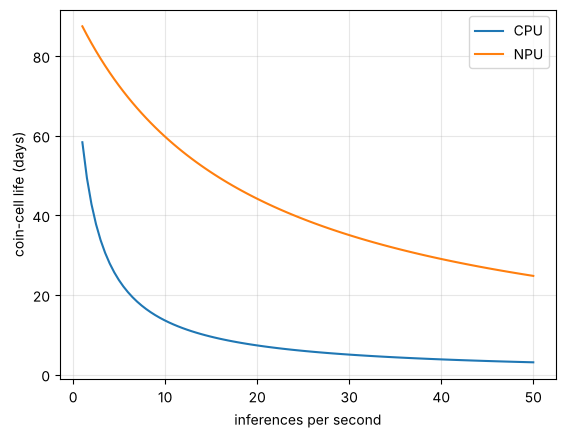

In [3]:
rates = np.linspace(1, 50, 100)
E_cpu = 20e-3 * em.inference_time_s(macs, 1.5, 200e6)
E_npu = 40e-3 * em.inference_time_s(macs, 128, 200e6, 0.25)
for E, lab in ((E_cpu, 'CPU'), (E_npu, 'NPU')):
    plt.plot(rates, [em.life_days(E_coin, em.average_power_w(r, E, P_cont)) for r in rates], label=lab)
plt.xlabel('inferences per second'); plt.ylabel('coin-cell life (days)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · Airtime against spreading factor

Example 27-08.3: a 20-byte packet at 125 kHz, CR 4/5, 8-symbol preamble, explicit header, CRC.

**Predict:** the time on air at SF9.

In [4]:
for sf in range(7, 13):
    t = em.lora_time_on_air_s(20, sf)
    print(f"SF{sf}: {1e3*t:7.1f} ms, {em.max_messages(36, t):4d} packets/hour at 1%")

SF7:    56.6 ms,  636 packets/hour at 1%
SF8:   102.9 ms,  349 packets/hour at 1%
SF9:   185.3 ms,  194 packets/hour at 1%
SF10:   370.7 ms,   97 packets/hour at 1%
SF11:   741.4 ms,   48 packets/hour at 1%
SF12:  1318.9 ms,   27 packets/hour at 1%


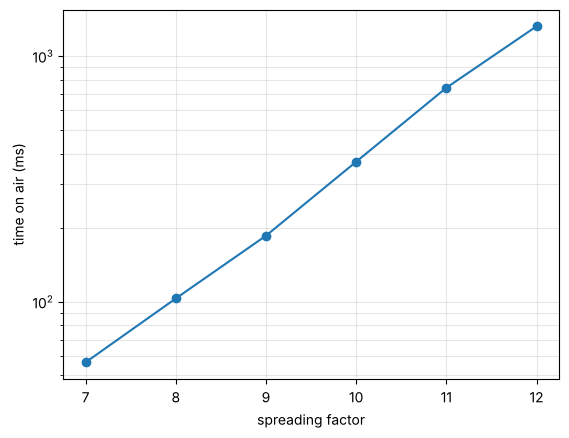

In [5]:
sfs = range(7, 13)
plt.semilogy(list(sfs), [1e3 * em.lora_time_on_air_s(20, sf) for sf in sfs], 'o-')
plt.xlabel('spreading factor'); plt.ylabel('time on air (ms)'); plt.grid(True, alpha=0.3, which='both'); plt.show()

## Part 3 · Battery life

Example 27-08.4: 96 messages a day, 2.6 Ah at 3.6 V, 80% usable, 1% a year self-discharge, 10 µW sleep.

**Predict:** the life at SF10, with self-discharge.

In [6]:
V = 3.3
usable = 0.8 * 2.6 * 3.6 * 3600; sd_day = 0.01 * 2.6 * 3.6 * 3600 / 365
def msg(sf):
    t = em.lora_time_on_air_s(20, sf); ts = em.lora_symbol_s(sf, 125e3)
    return t * 0.029 * V + 2 * 5 * ts * 0.0108 * V + 0.005 * V * 0.05
def life_years(sf, per_day=96):
    return usable / (per_day * msg(sf) + 10e-6 * 86400 + sd_day) / 365
for sf in (7, 10, 12):
    print(f"SF{sf}: {1e3*msg(sf):.1f} mJ per message, {life_years(sf):.1f} years")

SF7: 6.6 mJ per message, 30.5 years
SF10: 39.2 mJ per message, 13.3 years
SF12: 138.7 mJ per message, 4.9 years


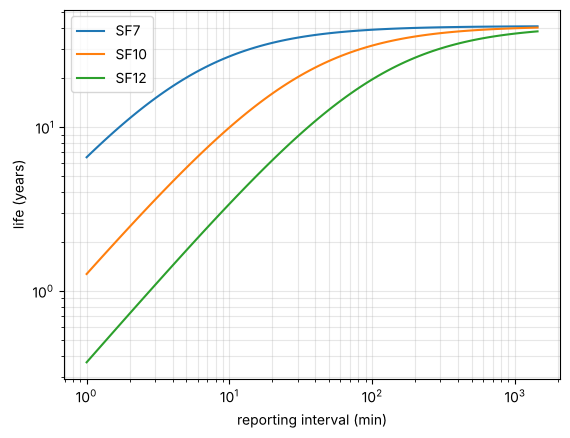

In [7]:
minutes = np.logspace(0, math.log10(1440), 100)
for sf in (7, 10, 12):
    plt.loglog(minutes, [life_years(sf, 1440 / m) for m in minutes], label=f'SF{sf}')
plt.xlabel('reporting interval (min)'); plt.ylabel('life (years)'); plt.legend(); plt.grid(True, alpha=0.3, which='both'); plt.show()

## Part 4 · Three dark days

Example 27-08.5: the SF7 node averages 17.3 µW; a 20 cm² cell, 300 lm/W, 20% cell and 80% converter efficiency, 10 lit hours a day; supercapacitor from 4.0 V to 2.2 V.

**Predict:** the supercapacitor for 72 hours of darkness.

In [8]:
p_avg = (96 * msg(7) + 10e-6 * 86400) / 86400
for hours in (16, 62, 72):
    E = p_avg * hours * 3600
    print(f"{hours} h: {E:.2f} J, C = {em.capacitor_for_energy_f(E, 4.0, 2.2):.3f} F")

16 h: 1.00 J, C = 0.179 F
62 h: 3.87 J, C = 0.694 F
72 h: 4.49 J, C = 0.805 F


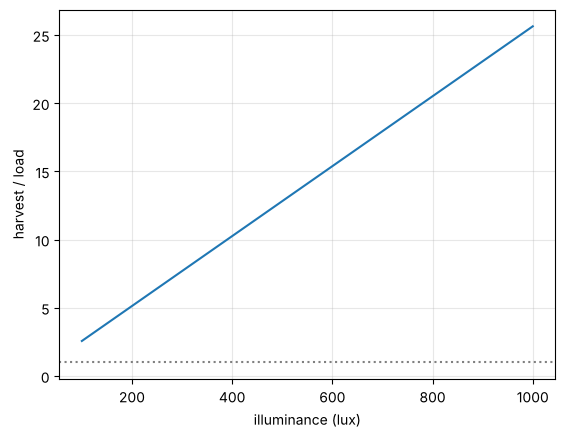

In [9]:
lux = np.linspace(100, 1000, 100)
margin = [em.pv_power_w(L, 20e-4, 300, 0.2, 0.8) * 36000 / (p_avg * 86400) for L in lux]
plt.plot(lux, margin); plt.axhline(1, color='0.5', ls=':')
plt.xlabel('illuminance (lux)'); plt.ylabel('harvest / load'); plt.grid(True, alpha=0.3); plt.show()

## Discussion

Compare your predictions with the lab README's expected results. Which lever moved each answer most: NPU utilization, the front end, the spreading factor, the reporting interval or the cell?